# 14 · Error of the final models by number of reactions

Reactions are known when an estimate is made, so these tables can be used in practice: given a post's reactions, how far off can we be? Final in-platform model: CatBoost with MAE loss, followers + reactions + flags, default settings. Out-of-platform: ridge on likes and comments trained on the other two platforms.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, extra_models as em, modeling as mo, reaction_tiers as rt, transfer_matrix as tm

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
f, meta = em.load(ROOT); f2, _, meta2 = tm.load(ROOT); meta2 = meta2[meta2.platform.isin(tm.KNOWN) & meta2.y.notna()]; f2 = f2.loc[meta2.index]

## 1 · Typical error and 90% range per tier

In [3]:
T = pd.concat([rt.table(*rt.in_platform(f, meta, p), p, "same platform") for p in mo.PLATS] + [rt.table(*rt.other_platforms(f2, meta2, p), p, "other platforms") for p in mo.PLATS], ignore_index=True); T.round(2)

,platform,model,reactions,posts,MAE,low,high,typical factor,90% factor,bias
0,TikTok,same platform,0,84,0.52,0.40,0.62,3.28,21.87,-0.30
1,TikTok,same platform,1-10,526,0.29,0.26,0.32,1.93,4.31,0.00
2,TikTok,same platform,11-100,1120,0.24,0.23,0.25,1.73,3.27,0.04
3,TikTok,same platform,101-1000,532,0.29,0.27,0.31,1.94,4.03,0.03
4,TikTok,same platform,>1000,229,0.29,0.26,0.33,1.94,4.03,0.07
5,TikTok,same platform,all,2491,0.27,0.26,0.29,1.88,3.90,0.02
6,YouTube,same platform,0,665,0.66,0.62,0.72,4.60,19.17,0.02
7,YouTube,same platform,1-10,613,0.45,0.42,0.47,2.80,7.48,0.01
8,YouTube,same platform,11-100,631,0.37,0.35,0.40,2.36,5.44,0.09
9,YouTube,same platform,101-1000,394,0.32,0.29,0.35,2.08,4.57,0.04


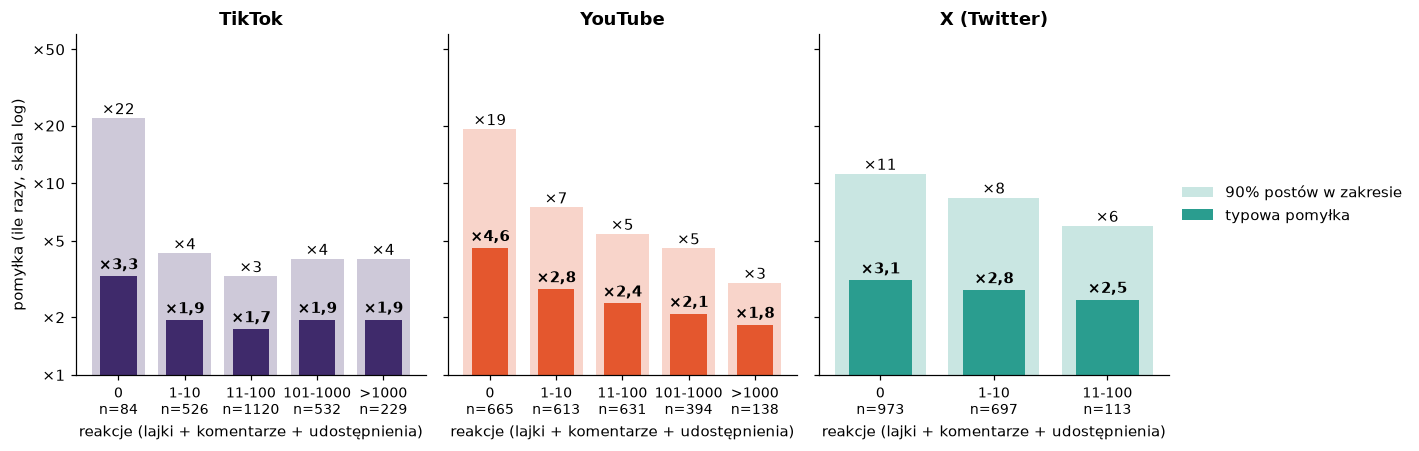

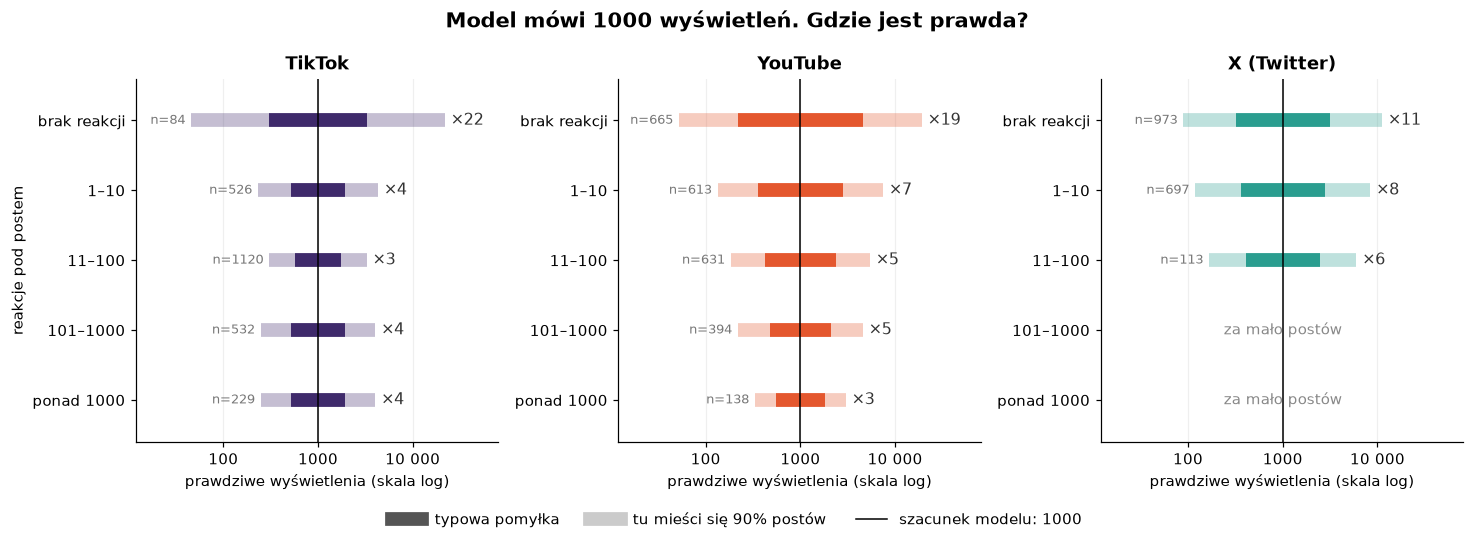

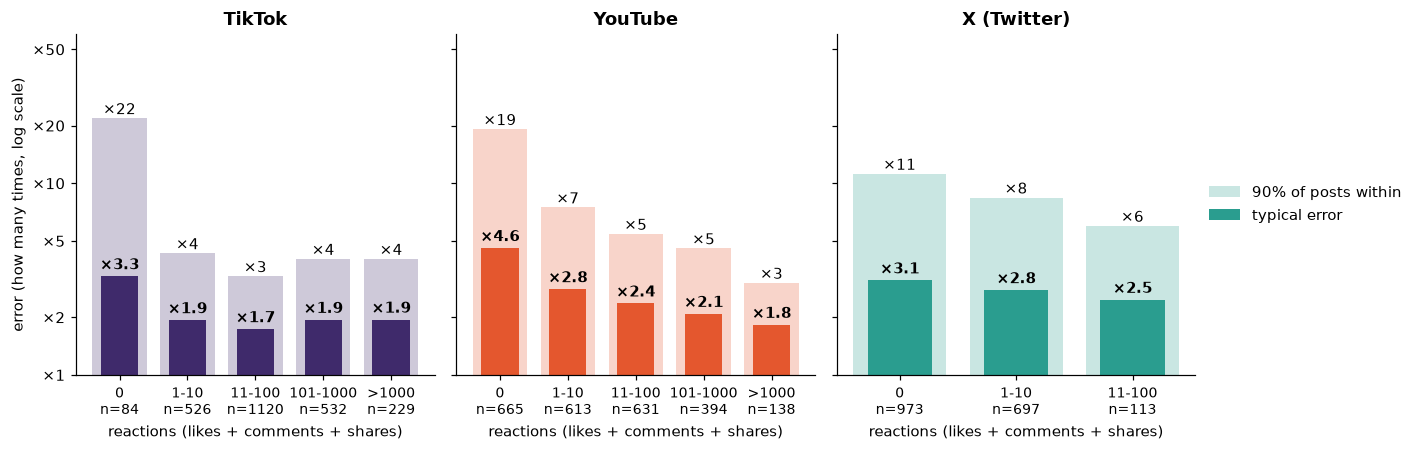

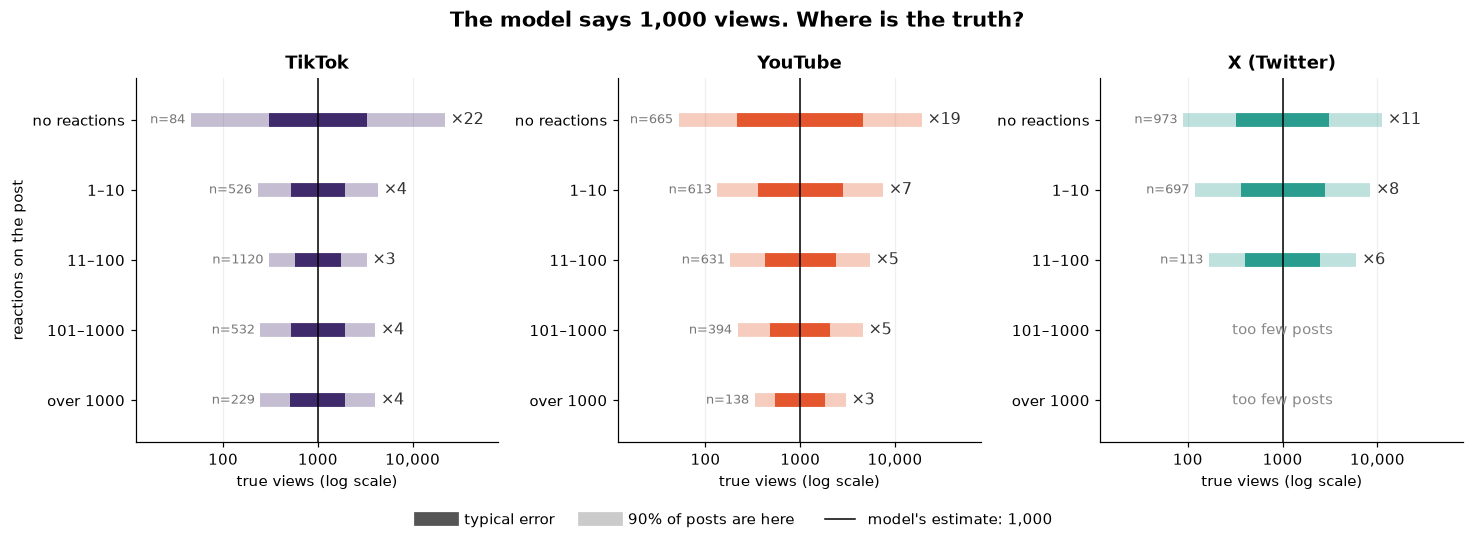

In [4]:
for l in ('pl', 'en'): rt.plot(T, FIG / f'reaction_tiers_{l}.png', l); rt.plot_ranges(T, FIG / f'reaction_ranges_{l}.png', l)

## 2 · Intervals: one width or one per tier?

In [5]:
C = pd.concat([rt.conformal(f, meta, p) for p in mo.PLATS], ignore_index=True); C.round(2)

,platform,reactions,posts,one width: coverage,one width: factor,per tier: coverage,per tier: factor
0,TikTok,0,84,0.67,4.28,0.67,4.28
1,TikTok,1-10,526,0.89,4.26,0.92,5.22
2,TikTok,11-100,1120,0.94,4.28,0.90,3.27
3,TikTok,101-1000,532,0.90,4.23,0.90,4.06
4,TikTok,>1000,229,0.92,4.27,0.93,4.66
5,TikTok,all,2491,0.91,4.26,0.90,3.94
6,YouTube,0,665,0.76,9.07,0.89,17.19
7,YouTube,1-10,613,0.92,9.04,0.90,7.77
8,YouTube,11-100,631,0.96,9.02,0.91,6.21
9,YouTube,101-1000,394,0.97,9.07,0.91,4.81


## Takeaways
- **More reactions, smaller error on YouTube and X:** YouTube ×4.6 at zero reactions to ×1.8 above 1,000; X ×3.1 to ×2.5. TikTok is flat at about ×1.7-1.9 once a post has any reaction, and ×3.3 at zero.
- **One interval width misleads:** it covers only 67% / 76% / 87% of zero-reaction posts against a 90% target, and 95-98% at high reactions on YouTube and X.
- **One width per reaction tier fixes most of this:** coverage 89-96% where the tier has enough calibration data, with YouTube's width from ×17 at zero reactions down to ×5 at 101-1000. TikTok's zero tier has only 84 posts and falls back to the shared width, so it stays at 67%.
- **Out of platform, zero-reaction posts are the weak spot:** YouTube ×13, X ×5.5. With reactions, the move costs far less.
- Tiers of reactions can be used in practice because reactions are known when estimating; tiers of true views cannot.

In [6]:
json.dump({"tiers": T.to_dict("records"), "conformal": C.to_dict("records")}, open(ROOT / "data" / "processed" / "tiers_numbers.json", "w"), indent=1, default=float)